In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.6 MB/s eta 0:00:00


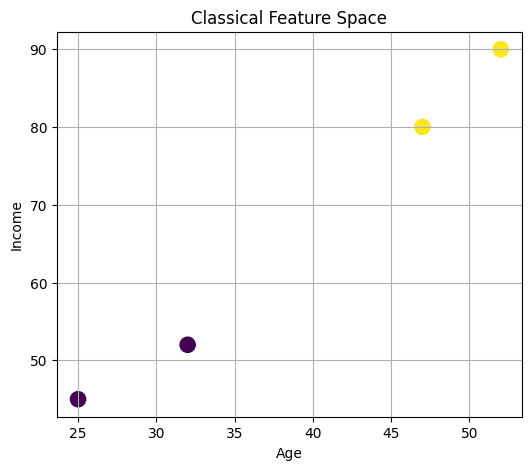

--- 1. 파라미터가 살아있는 원본 회로 설계도 ---


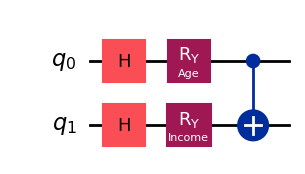

--- 2. 첫 번째 고객 데이터가 대입(Bound)된 회로 ---


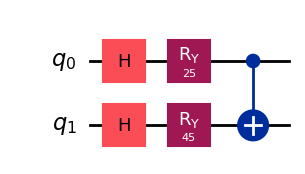

--- 3. Qiskit 공식 ZZ Feature Map 회로 ---


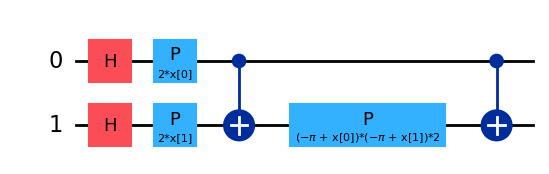

--- 4. 최종 양자 상태 벡터 (Statevector) ---
Statevector([-0.20544443+0.j, -0.6336271 +0.j, -0.72385666+0.j,
             -0.17983555+0.j],
            dims=(2, 2))


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit.circuit import Parameter
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector

# 1. 고전 데이터셋 및 산점도 시각화
customer = pd.DataFrame({
    "Age": [25, 32, 47, 52],
    "Income": [45, 52, 80, 90],
    "VIP": [0, 0, 1, 1]
})

plt.figure(figsize=(6, 5))
plt.scatter(
    customer["Age"],
    customer["Income"],
    c=customer["VIP"],
    s=120
)
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Classical Feature Space")
plt.grid(True)
plt.show()  # 고전 그래프 먼저 출력

# 2. 파라미터 기반 커스텀 회로 설계
age = Parameter("Age")
income = Parameter("Income")

qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)
qc.ry(age, 0)
qc.ry(income, 1)
qc.cx(0, 1)

print("--- 1. 파라미터가 살아있는 원본 회로 설계도 ---")
display(qc.draw("mpl"))

# 3. 실제 데이터(Age: 25, Income: 45) 바인딩
bound_qc = qc.assign_parameters({
    age: 25,
    income: 45
})

print("--- 2. 첫 번째 고객 데이터가 대입(Bound)된 회로 ---")
display(bound_qc.draw("mpl"))

# 4. Qiskit 공식 ZZ Feature Map 구조 비교
feature_map = zz_feature_map(
    feature_dimension=2,
    reps=1
)

print("--- 3. Qiskit 공식 ZZ Feature Map 회로 ---")
display(feature_map.draw("mpl"))

# 5. 상태 벡터(Statevector) 계산 및 출력
# 측정을 거치기 전, 양자 회로가 만들어낸 최종 양자 상태의 진폭과 위상(수학적 벡터)을 직접 확인합니다.
state = Statevector.from_instruction(bound_qc)

print("--- 4. 최종 양자 상태 벡터 (Statevector) ---")
print(state)